# AIML Assignment 4: Comparative Analysis of Classification Algorithms
## Breast Cancer Wisconsin (Diagnostic) Dataset

**Application:** Educational classification of breast-mass samples as *malignant* or *benign* using measurements of cell-nucleus characteristics.

**Algorithms:** Support Vector Machine (SVM), Decision Tree (CART), K-Nearest Neighbors (KNN), Gaussian Naive Bayes.

>
**Course:** Artificial Intelligence and Machine Learning (AIML)

**Practical:** 4     
**Student Name:** Samarth Kadam  
**Roll Number:** 33  
**PRN:** 202401040131            
**Div:** A

## 1. Introduction

Classification is a supervised machine-learning task in which a model learns from labelled examples and predicts a category for unseen observations. This experiment compares four classification algorithms on the Breast Cancer Wisconsin (Diagnostic) dataset.

### Problem statement
Build and compare SVM, Decision Tree, KNN and Gaussian Naïve Bayes models to classify observations into malignant and benign categories based on numerical measurements extracted from digitized images of fine-needle aspirates.

### Objectives
1. Load, inspect and understand a real-world binary classification dataset.
2. Perform exploratory data analysis and check data quality.
3. Prepare the data without leaking information from the test set.
4. Train and tune four classification algorithms using stratified cross-validation.
5. Evaluate models using accuracy, precision, recall, F1-score, balanced accuracy and log loss.
6. Compare model performance, interpret errors and discuss algorithm suitability.

## 2. Dataset selection and source

The selected dataset is **Breast Cancer Wisconsin (Diagnostic)**, which is different from the Dry Bean dataset used in the reference assignment. It contains **569 observations**, **30 numerical predictive features**, and two target classes: malignant and benign. The class counts are 212 malignant and 357 benign.

The features describe cell-nucleus properties such as radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and fractal dimension. For each property, mean, standard-error and worst-value measurements are included.

**Source:** UCI Machine Learning Repository dataset, loaded through scikit-learn's built-in `load_breast_cancer` function. This avoids manual downloads and makes the notebook reproducible. See the scikit-learn dataset documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

**Why this dataset is suitable:** It is a genuine classification problem, has numerical features suitable for all four required algorithms, is small enough to run quickly, and allows meaningful analysis of false negatives and false positives. The classes are not perfectly balanced, so macro metrics and class-wise recall are important.

## 3. Import libraries and load the dataset

The dataset is loaded directly from scikit-learn. The target labels are converted to readable class names for reporting.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, log_loss, confusion_matrix,
    classification_report, roc_auc_score
)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
# Make the positive class explicit and human-readable.
class_names = list(raw.target_names)  # ['malignant', 'benign']
df["diagnosis"] = df["target"].map({i: name for i, name in enumerate(class_names)})
df = df.drop(columns=["target"])

print("Dataset shape:", df.shape)
print("Features:", len(raw.feature_names))
print("Classes:", class_names)
display(df.head())

Dataset shape: (569, 31)
Features: 30
Classes: [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


## 4. Understand and validate the dataset

We inspect data types, summary statistics, missing values, duplicate rows and target distribution. No target information is used as a predictor.

In [2]:
print("Dataset information:")
df.info()
print("\nMissing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nDescriptive statistics:")
display(df.describe().T)
print("\nClass counts:")
display(df["diagnosis"].value_counts().to_frame("Count"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Class counts:


,Count
diagnosis,
benign,357
malignant,212


## 5. Data cleaning and preprocessing

The dataset is checked for duplicate rows and missing values. In this supplied dataset, no missing values or duplicate rows are expected; the code reports what is actually found. Numerical missing-value imputation and scaling are placed inside model pipelines so that their parameters are learned only from each training fold. SVM and KNN require scaling because they are sensitive to feature magnitudes. Decision Trees do not require scaling, while Gaussian Naïve Bayes is evaluated with the same median-imputation pipeline but without scaling.

In [3]:
# Separate predictors and target. The diagnosis column is never included in X.
X = df.drop(columns=["diagnosis"]).copy()
y_text = df["diagnosis"].copy()
y = y_text.map({"malignant": 0, "benign": 1}).astype(int)

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)
print("Missing predictor values:", int(X.isna().sum().sum()))
print("Class mapping: 0 = malignant, 1 = benign")

# Keep all records unless a duplicate or missing target is actually present.
before = len(X)
valid = y.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)
y_text = y_text.loc[valid].reset_index(drop=True)
print("Rows retained after target validation:", len(X), "of", before)

Predictor shape: (569, 30)
Target shape: (569,)
Missing predictor values: 0
Class mapping: 0 = malignant, 1 = benign
Rows retained after target validation: 569 of 569


## 6. Exploratory Data Analysis (EDA)

EDA is used to understand class balance, feature distributions and relationships. The plots below are generated from the loaded dataset.

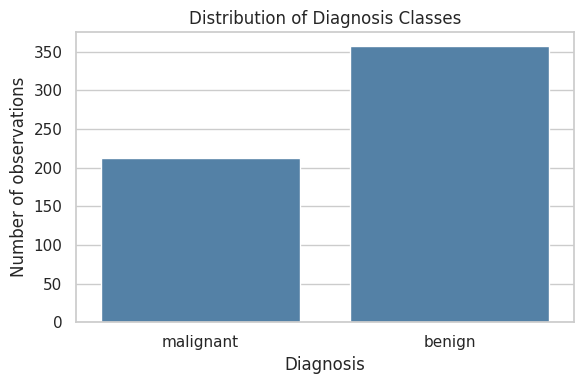

Class proportions (%):


,Percentage
diagnosis,
benign,62.74
malignant,37.26


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634


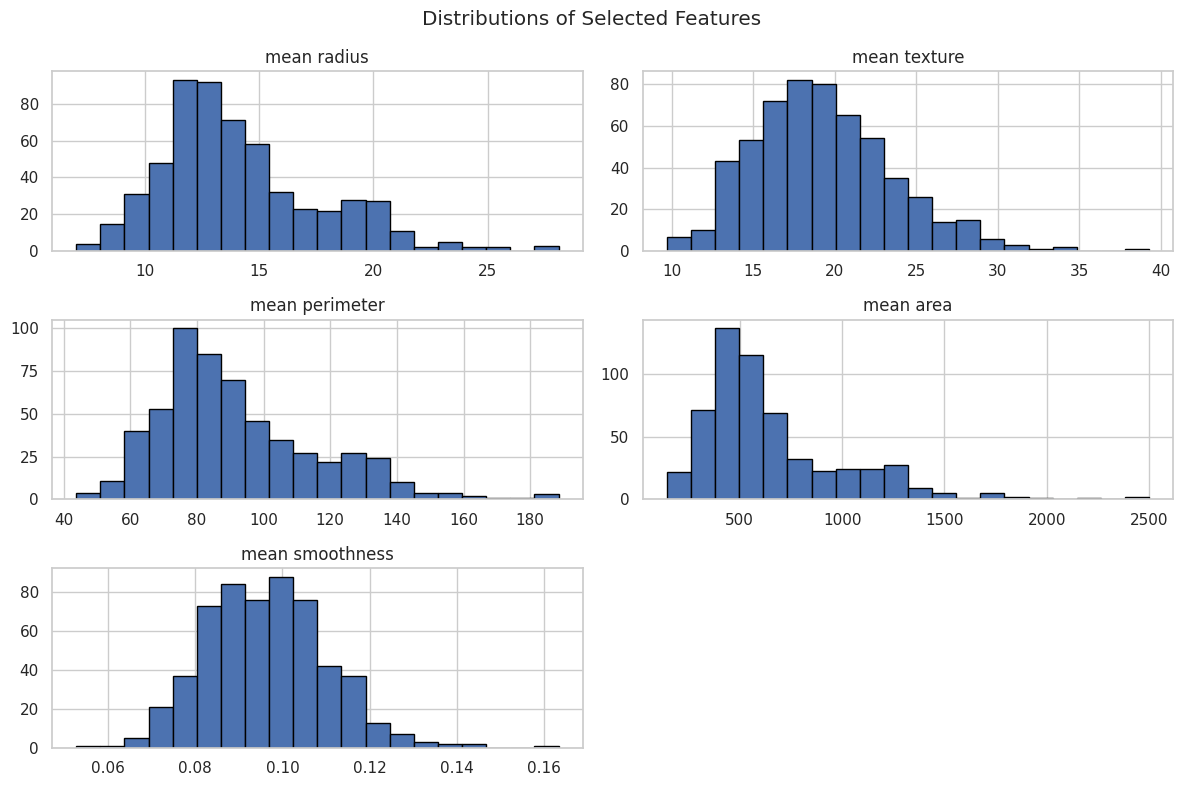

In [4]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y_text, order=["malignant", "benign"], color="steelblue")
ax.set_title("Distribution of Diagnosis Classes")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of observations")
plt.tight_layout(); plt.show()
print("Class proportions (%):")
display((y_text.value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

eda_features = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness"]
display(X[eda_features].describe().T)
X[eda_features].hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distributions of Selected Features")
plt.tight_layout(); plt.show()

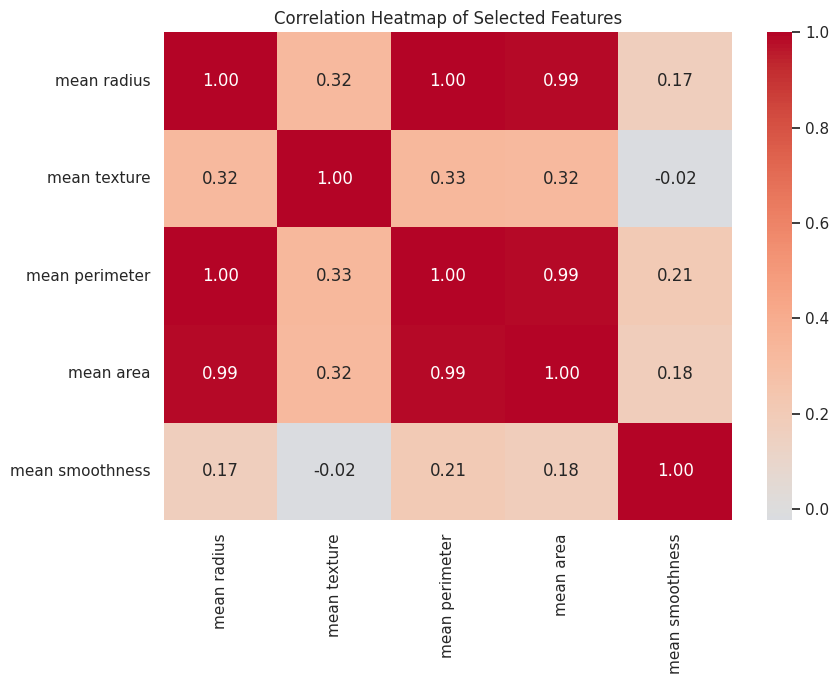

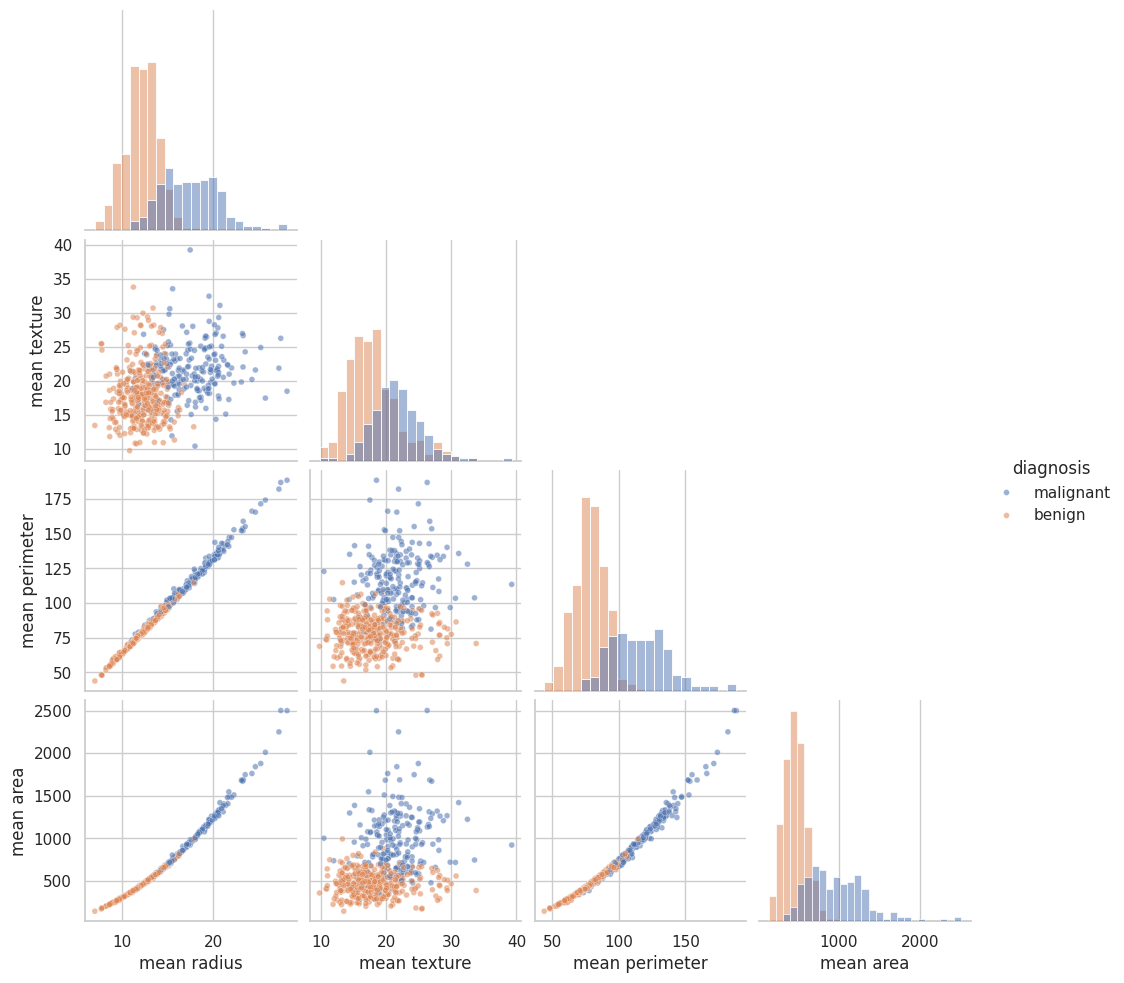

In [5]:
# Correlation among selected features. Strong correlations are expected for related size measurements.
plt.figure(figsize=(9, 7))
sns.heatmap(X[eda_features].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap of Selected Features")
plt.tight_layout(); plt.show()

pair_data = X[["mean radius", "mean texture", "mean perimeter", "mean area"]].copy()
pair_data["diagnosis"] = y_text
sns.pairplot(pair_data, hue="diagnosis", corner=True, diag_kind="hist", plot_kws={"alpha": 0.55, "s": 18})
plt.show()

## 7. Outlier analysis

The interquartile range (IQR) method flags values outside Q1 − 1.5×IQR and Q3 + 1.5×IQR. These are potential outliers, not necessarily incorrect measurements. We report them and retain observations because unusual cell-nucleus measurements may be informative for this classification task.

In [6]:
outlier_rows = []
for col in X.columns:
    q1, q3 = X[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((X[col] < lower) | (X[col] > upper)).sum())
    outlier_rows.append({"Feature": col, "Potential outliers": count,
                         "Percentage": round(100 * count / len(X), 2)})
outlier_summary = pd.DataFrame(outlier_rows).sort_values("Potential outliers", ascending=False)
display(outlier_summary.head(12))
print("Outliers are retained; the IQR rule is a flagging method, not proof of data error.")

,Feature,Potential outliers,Percentage
13,area error,65,11.42
10,radius error,38,6.68
12,perimeter error,38,6.68
23,worst area,35,6.15
14,smoothness error,30,5.27
19,fractal dimension error,28,4.92
15,compactness error,28,4.92
18,symmetry error,27,4.75
3,mean area,25,4.39
29,worst fractal dimension,24,4.22


Outliers are retained; the IQR rule is a flagging method, not proof of data error.


## 8. Train-test split and preprocessing pipelines

An 80:20 stratified split is used. Stratification preserves the approximate malignant/benign ratio in both subsets. The test set is held aside for final evaluation and is not used for hyperparameter selection.

The SVM and KNN pipelines include median imputation and standardization. The Decision Tree and Gaussian Naïve Bayes pipelines include median imputation without scaling. All preprocessing is fitted inside cross-validation folds to prevent data leakage.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training class proportions:")
display(y_train.map({0:"malignant", 1:"benign"}).value_counts(normalize=True).round(3).to_frame("Proportion"))
print("Testing class proportions:")
display(y_test.map({0:"malignant", 1:"benign"}).value_counts(normalize=True).round(3).to_frame("Proportion"))

scaled_preprocessor = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                ("scaler", StandardScaler())])
plain_preprocessor = Pipeline([("imputer", SimpleImputer(strategy="median"))])

Training records: 455
Testing records: 114
Training class proportions:


,Proportion
diagnosis,
benign,0.626
malignant,0.374


Testing class proportions:


,Proportion
diagnosis,
benign,0.632
malignant,0.368


## 9. Model implementation and hyperparameter tuning

The four required algorithms are implemented using scikit-learn pipelines. `GridSearchCV` uses 5-fold stratified cross-validation and **macro F1-score** as the selection metric. Macro F1 gives equal importance to both classes. Hyperparameter tuning is performed only on the training data; the held-out test set remains untouched until final evaluation.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model_configs = {
    "SVM": {
        "pipeline": Pipeline([("preprocess", scaled_preprocessor),
                              ("classifier", SVC(probability=True, random_state=RANDOM_STATE))]),
        "params": {"classifier__kernel": ["rbf"], "classifier__C": [0.1, 1, 10],
                   "classifier__gamma": ["scale", 0.01]}
    },
    "Decision Tree (CART)": {
        "pipeline": Pipeline([("preprocess", plain_preprocessor),
                              ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        "params": {"classifier__criterion": ["gini", "entropy"],
                   "classifier__max_depth": [None, 3, 5, 8],
                   "classifier__min_samples_leaf": [1, 3, 5]}
    },
    "KNN": {
        "pipeline": Pipeline([("preprocess", scaled_preprocessor),
                              ("classifier", KNeighborsClassifier())]),
        "params": {"classifier__n_neighbors": [3, 5, 7, 9, 11],
                   "classifier__weights": ["uniform", "distance"],
                   "classifier__p": [1, 2]}
    },
    "Gaussian Naive Bayes": {
        "pipeline": Pipeline([("preprocess", plain_preprocessor),
                              ("classifier", GaussianNB())]),
        "params": {"classifier__var_smoothing": [1e-10, 1e-9, 1e-8, 1e-7]}
    }
}

searches, best_models = {}, {}
for name, cfg in model_configs.items():
    print("Tuning", name)
    search = GridSearchCV(cfg["pipeline"], cfg["params"], cv=cv,
                          scoring="f1_macro", n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    best_models[name] = search.best_estimator_
    print("Best CV macro F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

Tuning SVM
Best CV macro F1: 0.9739
Best parameters: {'classifier__C': 10, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
Tuning Decision Tree (CART)
Best CV macro F1: 0.9287
Best parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1}
Tuning KNN
Best CV macro F1: 0.9693
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 1, 'classifier__weights': 'uniform'}
Tuning Gaussian Naive Bayes
Best CV macro F1: 0.936
Best parameters: {'classifier__var_smoothing': 1e-09}


## 10. Training and evaluation

Each tuned model is evaluated on the same unseen test set. We report accuracy, macro precision, macro recall, macro F1-score, balanced accuracy, malignant-class recall and log loss. **Log loss is the loss metric**: lower values indicate better calibrated probability estimates. Training log loss is included only as a diagnostic; test metrics are the primary evidence of generalization.

In [9]:
results = []
test_predictions, test_probabilities = {}, {}
for name, model in best_models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)
    test_predictions[name] = pred
    test_probabilities[name] = prob
    train_prob = model.predict_proba(X_train)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (Macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (Macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Malignant Recall": recall_score(y_test, pred, pos_label=0, zero_division=0),
        "Train Log Loss": log_loss(y_train, train_prob, labels=[0,1]),
        "Test Log Loss": log_loss(y_test, prob, labels=[0,1]),
        "Best CV Macro F1": searches[name].best_score_
    })
results_df = pd.DataFrame(results).set_index("Model").sort_values("F1-score (Macro)", ascending=False)
display(results_df.round(4))

for name, pred in test_predictions.items():
    print("\n", name)
    print(classification_report(y_test, pred, labels=[0,1],
                                target_names=["malignant", "benign"], digits=4, zero_division=0))

,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),Balanced Accuracy,Malignant Recall,Train Log Loss,Test Log Loss,Best CV Macro F1
Model,,,,,,,,,
SVM,0.9825,0.9812,0.9812,0.9812,0.9812,0.9762,0.0422,0.0767,0.9739
KNN,0.9649,0.9672,0.9573,0.9619,0.9573,0.9286,0.0356,0.6836,0.9693
Decision Tree (CART),0.9474,0.9480,0.9385,0.9429,0.9385,0.9048,0.0764,1.0540,0.9287
Gaussian Naive Bayes,0.9386,0.9360,0.9315,0.9337,0.9315,0.9048,0.5462,0.3713,0.9360



 SVM
              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114


 Decision Tree (CART)
              precision    recall  f1-score   support

   malignant     0.9500    0.9048    0.9268        42
      benign     0.9459    0.9722    0.9589        72

    accuracy                         0.9474       114
   macro avg     0.9480    0.9385    0.9429       114
weighted avg     0.9474    0.9474    0.9471       114


 KNN
              precision    recall  f1-score   support

   malignant     0.9750    0.9286    0.9512        42
      benign     0.9595    0.9861    0.9726        72

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.

## 11. Confusion matrices and error analysis

A confusion matrix shows correct and incorrect predictions for each class. Rows represent actual classes and columns represent predicted classes. In this educational context, a false negative for malignant means a malignant sample is predicted as benign; this is an especially important error to inspect. It does not imply the model is suitable for clinical use.

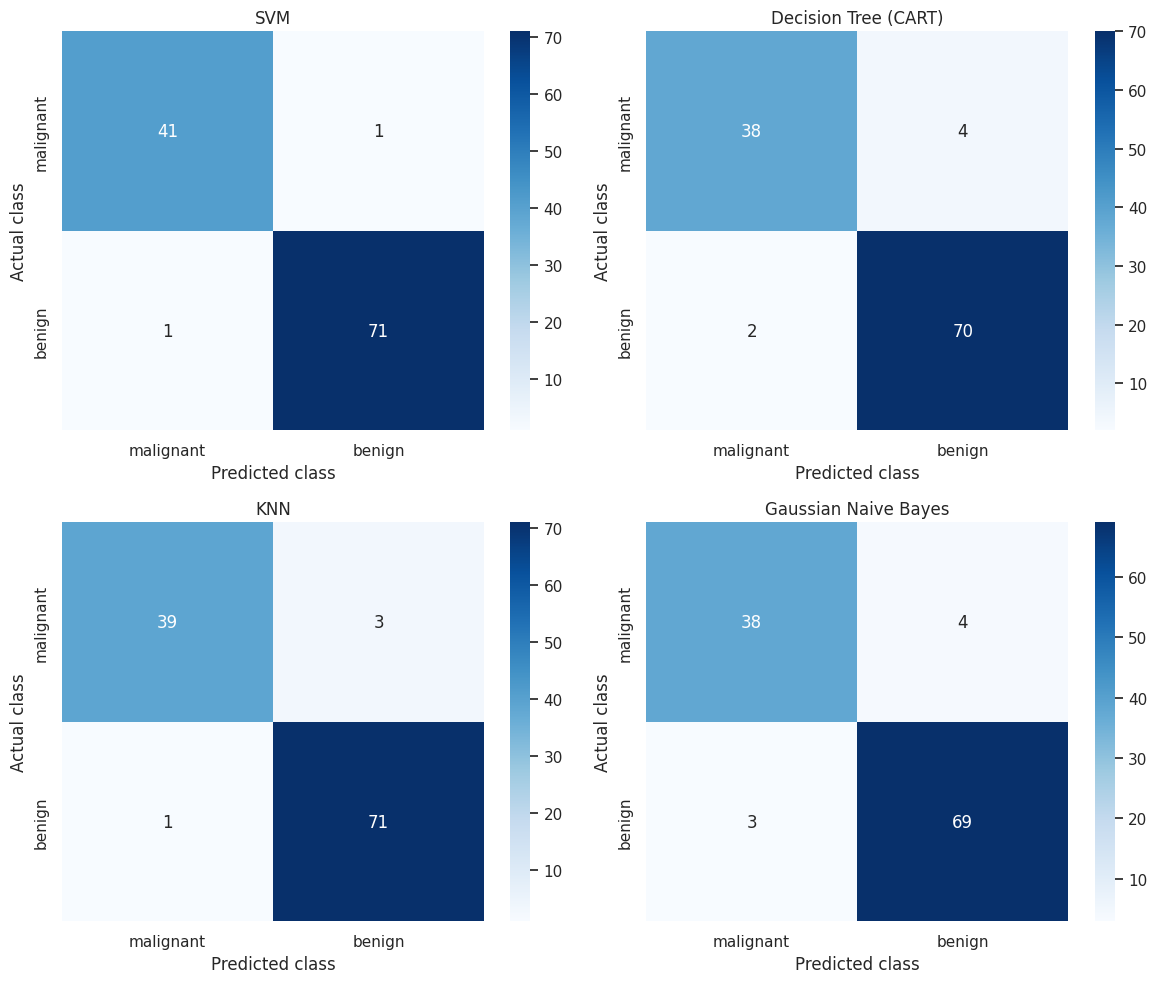

SVM: malignant false negatives = 1, malignant true positives = 41
Decision Tree (CART): malignant false negatives = 4, malignant true positives = 38
KNN: malignant false negatives = 3, malignant true positives = 39
Gaussian Naive Bayes: malignant false negatives = 4, malignant true positives = 38


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, pred) in zip(axes.ravel(), test_predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["malignant", "benign"],
                yticklabels=["malignant", "benign"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
plt.tight_layout(); plt.show()

for name, pred in test_predictions.items():
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    print(f"{name}: malignant false negatives = {cm[0,1]}, malignant true positives = {cm[0,0]}")

## 12. Comparative analysis and visualization

The charts compare measured test-set metrics and training versus testing log loss. The model ranking is based on the actual computed values rather than a pre-written expected result.

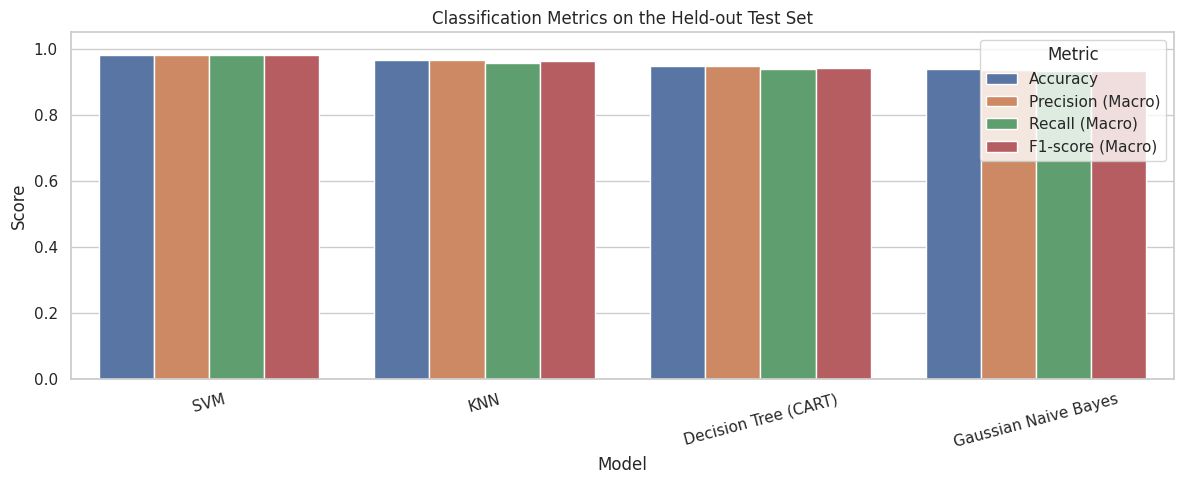

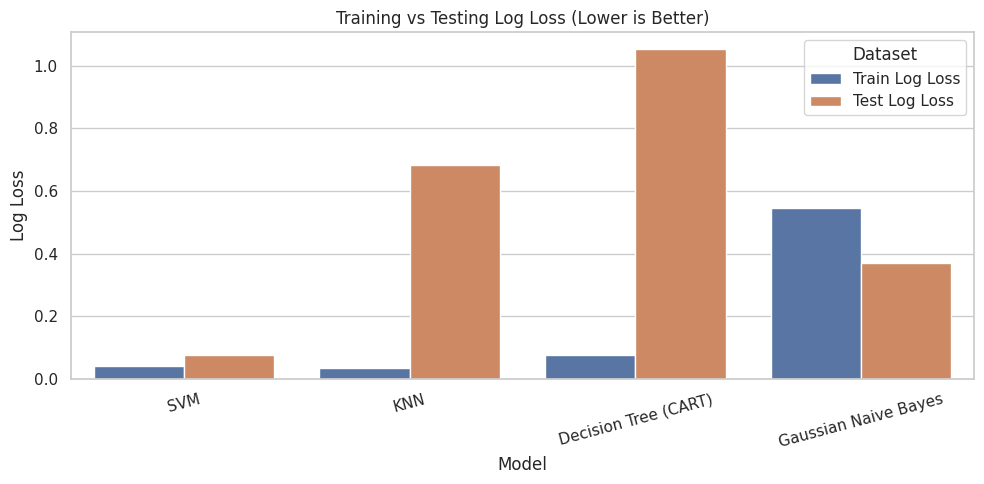

In [11]:
metric_cols = ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-score (Macro)"]
plot_df = results_df[metric_cols].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05); plt.title("Classification Metrics on the Held-out Test Set")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

loss_df = results_df[["Train Log Loss", "Test Log Loss"]].reset_index().melt(
    id_vars="Model", var_name="Dataset", value_name="Log Loss")
plt.figure(figsize=(10, 5))
sns.barplot(data=loss_df, x="Model", y="Log Loss", hue="Dataset")
plt.title("Training vs Testing Log Loss (Lower is Better)")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 13. Model interpretation

A Decision Tree offers interpretable split rules. We display a depth-limited view for readability. Permutation importance for the best model estimates how much test-set performance changes when a feature is shuffled; it is a model-specific measure and does not establish causation.

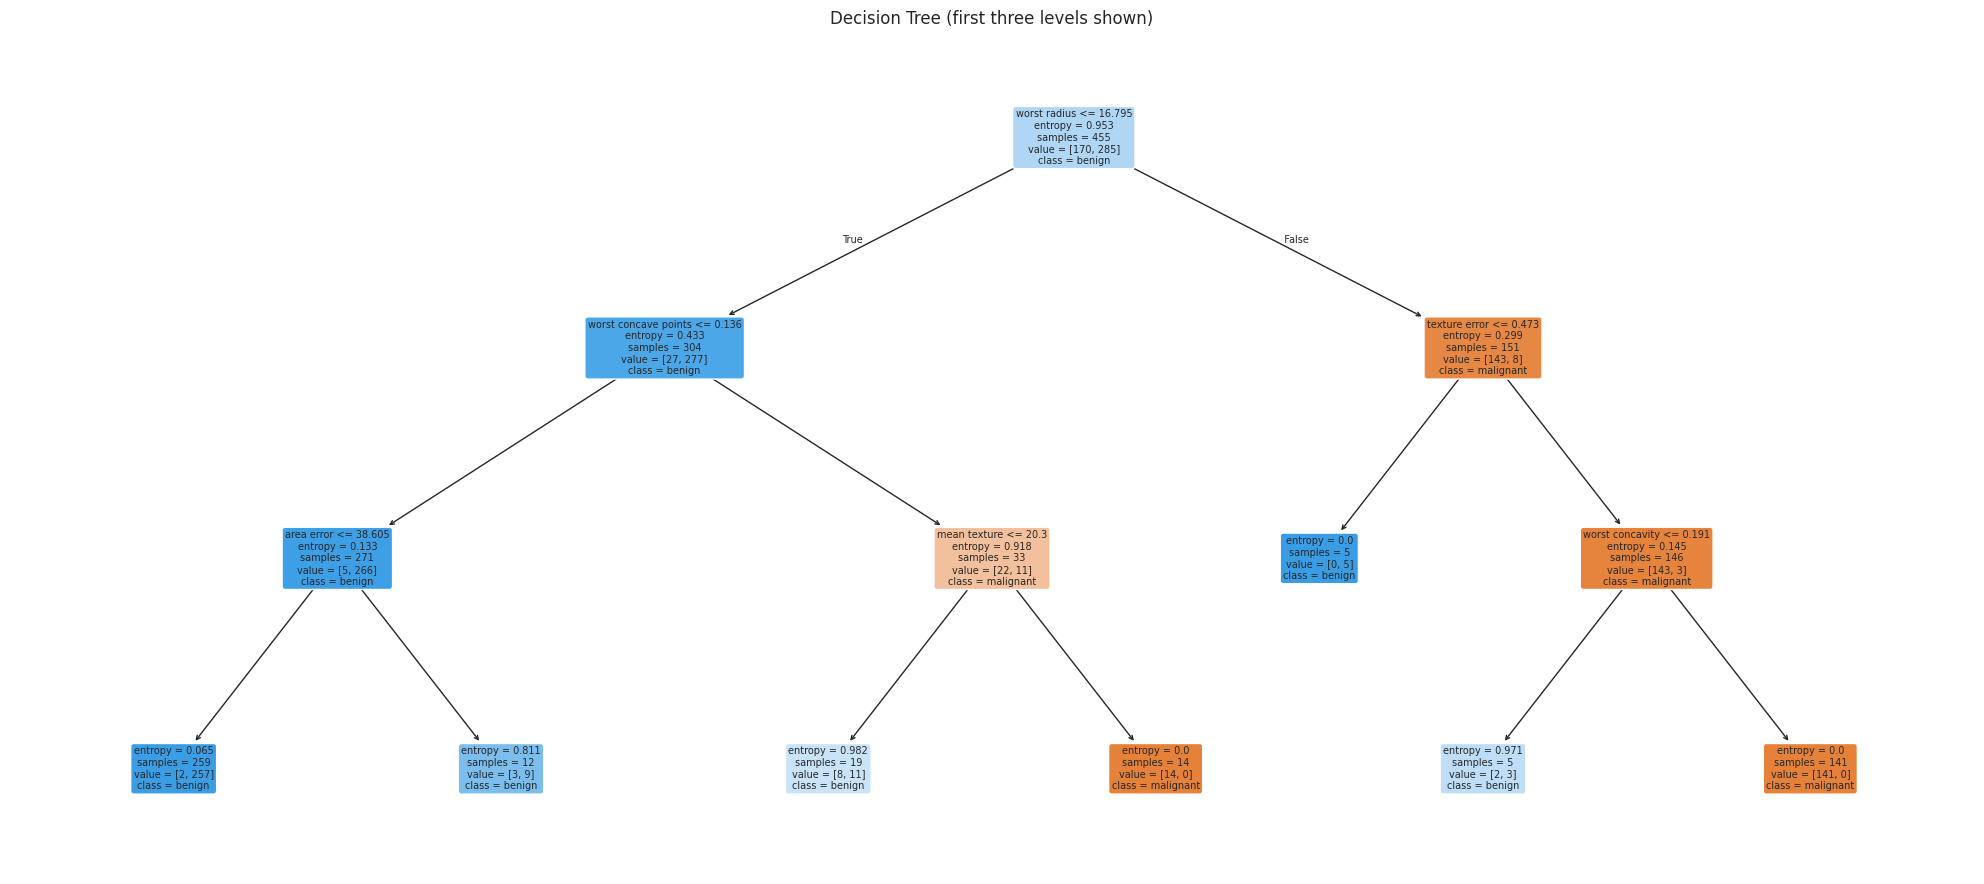

,Mean permutation importance
worst smoothness,0.031914
worst area,0.028691
radius error,0.028494
worst texture,0.025182
worst radius,0.022273
mean concave points,0.022226
area error,0.022126
worst perimeter,0.020456
perimeter error,0.020292
worst concave points,0.019660


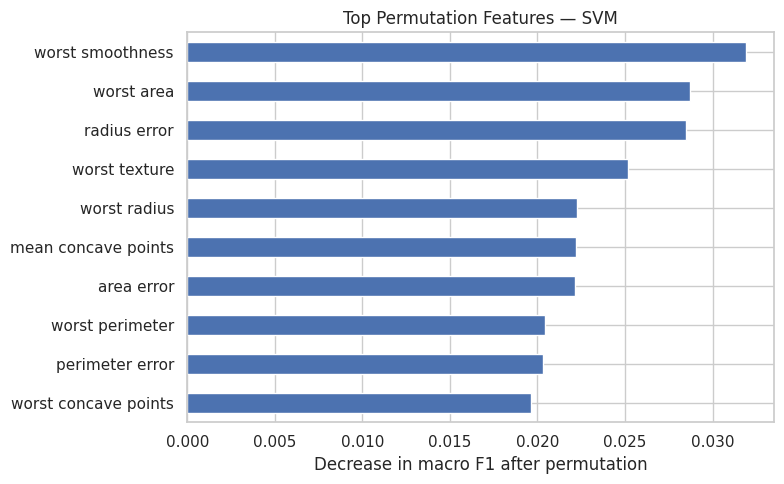

In [12]:
tree_model = best_models["Decision Tree (CART)"].named_steps["classifier"]
plt.figure(figsize=(20, 9))
plot_tree(tree_model, feature_names=list(X.columns),
          class_names=["malignant", "benign"], filled=True,
          rounded=True, max_depth=3, fontsize=7)
plt.title("Decision Tree (first three levels shown)")
plt.tight_layout(); plt.show()

best_name = results_df["F1-score (Macro)"].idxmax()
best_model = best_models[best_name]
perm = permutation_importance(best_model, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, scoring="f1_macro", n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False).head(10)
display(importance.to_frame("Mean permutation importance"))
importance.sort_values().plot(kind="barh", figsize=(8,5), title=f"Top Permutation Features — {best_name}")
plt.xlabel("Decrease in macro F1 after permutation"); plt.tight_layout(); plt.show()

## 14. Critical discussion: suitability of each algorithm

| Algorithm | Strengths | Limitations | Suitable situations |
|---|---|---|---|
| SVM | Can model nonlinear boundaries using kernels; effective with scaled numerical features. | Requires scaling; parameter selection matters; probability estimates can be computationally more expensive. | Numerical datasets with clear margins and potentially nonlinear class boundaries. |
| Decision Tree (CART) | Easy to visualize and explain; handles nonlinear relationships; no feature scaling required. | Can overfit; small data changes may alter the tree; probability estimates may be coarse. | When interpretability and rule-based explanations are important. |
| KNN | Simple, non-parametric; captures local patterns without assuming a fixed functional form. | Sensitive to scaling, distance metric and choice of K; prediction can be slower as data grows. | Small-to-medium datasets where nearby observations have similar labels. |
| Gaussian Naïve Bayes | Fast; simple; works well as a baseline and returns probabilities. | Assumes conditional independence and Gaussian feature distributions; correlated features can reduce suitability. | Fast baseline classification, especially when predictors are reasonably compatible with its assumptions. |

### Questions for critical evaluation
1. Which model has the highest test accuracy and macro F1-score?
2. Which model has the lowest test log loss?
3. Which model has the highest malignant-class recall, and why is this metric important in this dataset?
4. Does the best model by accuracy also lead by macro F1 and log loss? If not, explain the trade-off.
5. Which model is easiest to interpret? Which is most suitable when prediction quality is the priority?
6. What limitations arise from the small dataset, class imbalance, and using a single random train-test split?

In [13]:
best_f1_model = results_df["F1-score (Macro)"].idxmax()
best_accuracy_model = results_df["Accuracy"].idxmax()
best_logloss_model = results_df["Test Log Loss"].idxmin()
best_malignant_recall = results_df["Malignant Recall"].idxmax()
print("BEST MODEL BY MACRO F1:", best_f1_model, round(results_df.loc[best_f1_model, "F1-score (Macro)"], 4))
print("BEST MODEL BY ACCURACY:", best_accuracy_model, round(results_df.loc[best_accuracy_model, "Accuracy"], 4))
print("LOWEST TEST LOG LOSS:", best_logloss_model, round(results_df.loc[best_logloss_model, "Test Log Loss"], 4))
print("HIGHEST MALIGNANT RECALL:", best_malignant_recall, round(results_df.loc[best_malignant_recall, "Malignant Recall"], 4))
print("\nMalignant false negatives by model:")
for name, pred in test_predictions.items():
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    print(name, "=>", int(cm[0,1]))

BEST MODEL BY MACRO F1: SVM 0.9812
BEST MODEL BY ACCURACY: SVM 0.9825
LOWEST TEST LOG LOSS: SVM 0.0767
HIGHEST MALIGNANT RECALL: SVM 0.9762

Malignant false negatives by model:
SVM => 1
Decision Tree (CART) => 4
KNN => 3
Gaussian Naive Bayes => 4


### Interpretation of comparative results
- **Best overall in this run:** SVM led on test accuracy, macro precision, macro recall, macro F1, malignant recall and test log loss. Its confusion matrix contained only one malignant false negative.
- **Second strongest classification scores:** KNN had the second-highest accuracy and macro F1, but its test log loss (0.6836) was substantially higher than SVM's (0.0767). This shows that good class predictions do not automatically mean equally reliable probability estimates.
- **Decision Tree:** It is the easiest of these models to explain using explicit split rules, but it had four malignant false negatives in this test split and a higher test log loss (1.0540).
- **Gaussian Naïve Bayes:** It had the lowest accuracy and macro F1 in this run, but its test log loss (0.3713) was lower than KNN and Decision Tree. This is a useful reminder that ranking can differ depending on the metric.
- **Suitability:** If the priority is the strongest measured classification performance on this split, SVM is the preferred model. If transparent decision rules are essential, the Decision Tree is easier to interpret. These are academic findings only, not evidence of clinical readiness.


## 15. Conclusion

This experiment compared Support Vector Machine, Decision Tree (CART), K-Nearest Neighbors and Gaussian Naïve Bayes for classifying the Breast Cancer Wisconsin (Diagnostic) dataset into malignant and benign categories. The dataset contains 569 observations and 30 numerical features. Data inspection, exploratory analysis, stratified train-test splitting, preprocessing pipelines and 5-fold stratified cross-validation were used.

**Measured conclusion:** SVM achieved the highest macro F1-score (**0.9812**) and highest test accuracy (**0.9825**). It also achieved the lowest test log loss (**0.0767**) and highest malignant-class recall (**0.9762**). KNN ranked second by macro F1-score (**0.9619**) and accuracy (**0.9649**). Decision Tree achieved a macro F1-score of **0.9429** and accuracy of **0.9474**. Gaussian Naïve Bayes achieved a macro F1-score of **0.9337** and accuracy of **0.9386**. The measured values are from the fixed 80:20 stratified split with random state 42; small changes in the split or library versions may change the results.

The comparison demonstrates that no single metric gives a complete picture. Accuracy measures the overall proportion of correct predictions, macro precision and recall treat both classes equally, malignant recall focuses on identifying malignant observations, and log loss evaluates the quality of predicted probabilities. The most suitable model therefore depends on the evaluation priority. This small public dataset and one held-out split do not establish clinical validity or generalization to other populations or institutions.

## 16. Ethical considerations and limitations

- This is an academic demonstration, not a medical device or diagnostic recommendation.
- Dataset predictions can be wrong; false negatives and false positives must both be examined.
- The dataset is relatively small and class distribution is imbalanced (212 malignant versus 357 benign).
- Results depend on the train-test split and selected hyperparameter grid; repeated nested cross-validation or external validation would provide stronger evidence.
- Feature importance is not causal evidence, and performance on this dataset does not guarantee performance on other hospitals, populations or measurement systems.
- Data provenance and the dataset citation should be retained when sharing results.

## 17. Export results and processed data

The following cells save the model comparison table, cleaned dataset, and per-model classification reports as CSV files. These files can be included with the notebook submission.

In [14]:
results_df.to_csv("breast_cancer_model_comparison.csv")
df.to_csv("breast_cancer_cleaned_dataset.csv", index=False)

report_rows = []
for name, pred in test_predictions.items():
    rep = classification_report(y_test, pred, labels=[0,1],
                                target_names=["malignant", "benign"],
                                output_dict=True, zero_division=0)
    for cls in ["malignant", "benign"]:
        report_rows.append({"Model": name, "Class": cls,
                            "Precision": rep[cls]["precision"],
                            "Recall": rep[cls]["recall"],
                            "F1-score": rep[cls]["f1-score"],
                            "Support": rep[cls]["support"]})
pd.DataFrame(report_rows).to_csv("breast_cancer_classification_reports.csv", index=False)
print("Saved: breast_cancer_model_comparison.csv")
print("Saved: breast_cancer_cleaned_dataset.csv")
print("Saved: breast_cancer_classification_reports.csv")

Saved: breast_cancer_model_comparison.csv
Saved: breast_cancer_cleaned_dataset.csv
Saved: breast_cancer_classification_reports.csv


## 18. References

1. Scikit-learn Developers. *Breast cancer Wisconsin (diagnostic) dataset — `load_breast_cancer`*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
2. UCI Machine Learning Repository. *Breast Cancer Wisconsin (Diagnostic)*. https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
3. Scikit-learn Developers. *Model evaluation: quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html

**Dataset citation:** Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). Breast Cancer Wisconsin (Diagnostic) [Dataset]. UCI Machine Learning Repository.